# S-SZD: Example of usage

In this brief notebook, we show how to use the library for minimizing arbitrary functions. 
Specifically, the library can be used both for stochastic and deterministic zeroth order minimization  

In [18]:
import torch
import time
import numpy as np
import matplotlib.pyplot as plt
from sszd import SSZD
from sszd.direction_matrices import DirectionMatrix

rnd_state = np.random.RandomState(12)

## Zeroth order minimization
We consider the deterministic zeroth order minimization problem. Given a function $f: \mathbb{R}^d \rightarrow \mathbb{R}$, we want to find
$$
x^* \in \arg\min\limits_{x \in \mathbb{R}^d} f(x)
$$
where we can access only to function values $f(x)$.

We start by defining the problem we want to solve by considering the minimization of the following synthetic function $f(x) = x^2$ with $x \in \mathbb{R}$

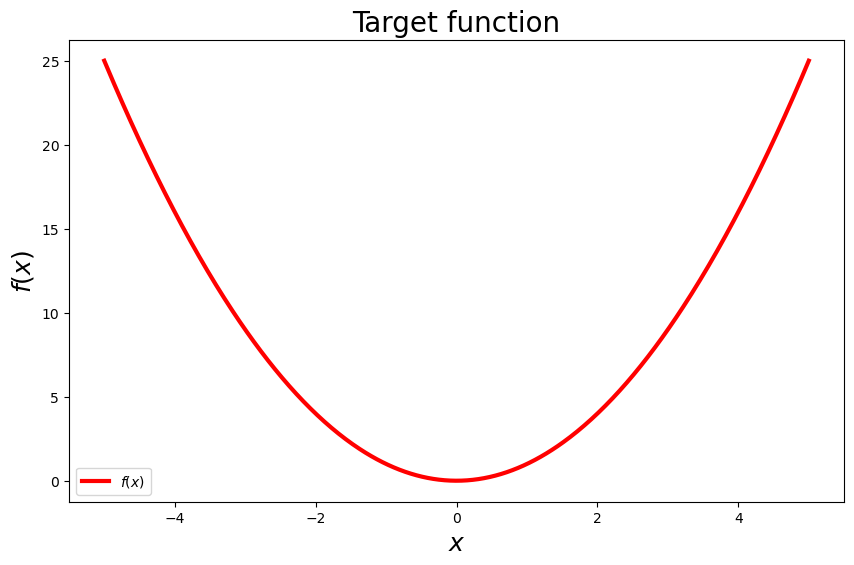

In [5]:
f = lambda x : x**2 # Target function
X = np.linspace(-5, 5, 500)
y = f(X)

_, ax = plt.subplots(figsize=(10, 6))
ax.set_title("Target function", fontsize=20)
ax.plot(X, y, '-', c="red", lw=3, label="$f(x)$")
ax.set_xlabel("$x$", fontsize=18)
ax.set_ylabel("$f(x)$", fontsize=18)
_ = ax.legend()

## Gram-Schimdt

In [130]:
class GSDirections(DirectionMatrix):
    def _compute_truncated_Q(self, A):
        Q = torch.zeros((self.d, self.l), dtype=self.dtype, device=self.device)
        for k in range(self.l):
            pr_sum = torch.zeros(self.d, dtype=self.dtype, device=self.device)
            for i in range(k):
                pr_sum +=A[:, k].dot(Q[:, i])/torch.linalg.norm(Q[:, i]) * Q[:, i]
            Q[:, k] = A[:, k] - pr_sum
            Q[:,k] = Q[:,k] / torch.linalg.norm(Q[:,k])
        return -Q
    
    def __call__(self):
        A = torch.randn(size=(self.d, self.l), generator=self.generator, device=self.device, dtype=self.dtype)
        return self._compute_truncated_Q(A)
        

In [135]:
28**2 * 3

2352

In [138]:
d = 2352
it_time = time.time()
torch.zeros((d, d), dtype=torch.float64, device='cpu')
it_time = time.time() - it_time
print(it_time)

0.010760068893432617


In [131]:
#    def __init__(self, d, l, seed=None, dtype=torch.float32, device='cpu'):
seed = 1212
dimensions = torch.logspace(1, 5, 5, dtype=torch.int) 
#gs_dir = GSDirections()
dimensions

tensor([    10,    100,   1000,  10000, 100000], dtype=torch.int32)

In [141]:
dimensions

ctimes = {}
d = 2352
#for d in dimensions:
ctimes[d] = []
gs_dir = GSDirections(d, d, seed=seed, dtype=torch.float64, device='cuda')
_ = gs_dir()
it_time = time.time()
P  = gs_dir()
it_time = time.time() - it_time
ctimes[d].append(it_time)

KeyboardInterrupt: 

In [140]:
ctimes

{2352: [0.005456686019897461]}